In [ ]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 1000 * us

n_rc=10
n_input_rows = n_rc  
n_input_columns = n_rc 
n_output_rows = n_rc  
n_output_columns = n_rc 
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 5, 5
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -60. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.1 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 3. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 5.5 * nS 
g_AMPA_rec_E = 5.5 * nS 
g_AMPA_ext_I = 5.5 * nS
g_AMPA_rec_I = 5.5 * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 1.0*nS 
g_GABA_I = 1.0*nS 
tau_GABA = 10. * ms


tau_HSP = 100*second           
target_rate = 2.0*Hz            
record_dt = 200*ms

tau_vm = 10*second
tau_active = 10*second
  

recurrent_radius = 2  


def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA,input_freq=40):
    # variables
    n_input_rows = 10  
    n_input_columns = 10 
    n_output_rows = 10 
    n_output_columns = 10
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 5, 5
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn + I_dbs) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp

    # Homeostatically scaled synaptic currents
    I_AMPA_ext = g_AMPA_ext_E  * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * k_AMPA_E_hsp  * (v - V_E) * s_AMPA : amp
    I_GABA_rec = g_GABA_E * k_GABA_E_hsp * (v - V_I) * s_GABA     : amp

    dI_dbs / dt = -I_dbs / (2*ms)  : amp

    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt      = - s_AMPA / tau_AMPA     : 1
    ds_GABA / dt      = - s_GABA / tau_GABA     : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    # HSP scaling variables (dimensionless)
    dk_AMPA_E_hsp/dt = ((1 - k_AMPA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_ins_AMPA_E
                - (k_AMPA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_int_AMPA_E) : 1

    dk_GABA_E_hsp/dt = (-(k_GABA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_int_GABA_E
                + (1 - k_GABA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_ins_GABA_E) : 1

    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    dy_act / dt = -y_act / tau_active : 1

    tau_ins_AMPA_E : second (shared)
    tau_int_AMPA_E : second (shared)
    tau_int_GABA_E : second (shared)
    tau_ins_GABA_E : second (shared)
    V_thr_E : volt
    tau_rp_E_var : second
    '''


    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * 0.3 * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

    I_GABA_rec = g_GABA_I * 0.3 * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz


    dy_act / dt = -y_act / tau_active : 1
    '''


    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr_E', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory='tau_rp_E_var', method='euler',name='P_E')
    P_E.v = V_L
    P_E.k_AMPA_E_hsp = 0.35  
    P_E.k_GABA_E_hsp = 0.35  
    P_E.tau_ins_AMPA_E = tau_ins_AMPA   #50'000
    P_E.tau_int_AMPA_E = tau_int_AMPA   #5'000
    P_E.tau_ins_GABA_E = tau_ins_GABA   
    P_E.tau_int_GABA_E = tau_int_GABA  
    P_E.V_thr_E = V_thr
    P_E.tau_rp_E_var = tau_rp_E

    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_I, method='euler',name='P_I')
    P_I.v = V_L


    pg_inp = PoissonGroup(N_inp, rates=input_freq * Hz, name = 'inp')

    
    C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre = '''
        s_AMPA_ext += w  
        ''', method='euler', name='PG_E')
    C_PG_E.connect(j='i')  

    
    C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre = '''
        s_AMPA += w  
        ''', method='euler', name='E_E')
    recurrent_radius = 2
    for y1 in range(n_output_rows):
        for x1 in range(n_output_columns):
            post = y1 * n_output_columns + x1
            for dy in range(-recurrent_radius, recurrent_radius + 1):
                for dx in range(-recurrent_radius, recurrent_radius + 1):
                    if dx == 0 and dy == 0:
                        continue
                    x2 = x1 + dx
                    y2 = y1 + dy
                    if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                        pre = y2 * n_output_columns + x2
                        C_E_E.connect(i=pre, j=post)
    C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='''
    s_AMPA += w
    ''', method='euler', name='E_I') #        x_postE_post += 1.0 
    C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
    for inh_idx, (ix, iy) in enumerate(inh_positions):
        for ex_y in range(n_output_rows):
            for ex_x in range(n_output_columns):
                if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                    exc_idx = ex_y * n_output_columns + ex_x
                    C_I_E.connect(i=inh_idx, j=exc_idx)
                    C_E_I.connect(i=exc_idx, j=inh_idx)
    C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
    for iy in range(n_inh_rows):
        for ix in range(n_inh_cols):
            post = iy * n_inh_cols + ix
            for dy in range(-1, 2):
                for dx in range(-1, 2):
                    if dx == 0 and dy == 0:
                        continue
                    x2, y2 = ix + dx, iy + dy
                    if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                        pre = y2 * n_inh_cols + x2
                        C_I_I.connect(i=pre, j=post)



    C_PG_E.w[:] = 1.1 #np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_PG_E.w)), 0.0, 1.0)#w_PG_E
    C_I_E.w[:] = np.clip(np.random.normal(loc=0.52, scale=0.05, size=len(C_I_E.w)), 0.0, 1.0)#w_I_E
    C_I_I.w[:] = np.clip(np.random.normal(loc=0.40, scale=0.05, size=len(C_I_I.w)), 0.0, 1.0)#w_I_I
    C_E_I.w[:] = 0.9#np.clip(np.random.normal(loc=0.40, scale=0.05, size=len(C_E_I.w)), 0.0, 1.0)#w_E_I Na blocker so 0.40 to 38
    C_E_E.w[:] = np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_E_E.w)), 0.0, 1.0)#w_E_E Na blocker so 0.32 to 0.3

    #DBS: 
    pg_dbs = PoissonGroup(N_E, rates=0*Hz, name='dbs')       # OFF: 0 Hz
    C_DBS_E = Synapses(pg_dbs, P_E, model='w_dbs : amp',
                       on_pre='I_dbs_post += w_dbs',
                       method='euler', name='DBS_E')
    C_DBS_E.connect(j='i')                                   # DBS i -> E neuron i
    C_DBS_E.w_dbs = 0*pA                                     # OFF: no current

    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', 
                method='euler')
    C_vm.connect()

    act_container = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act = Synapses(
        P_E, act_container,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act.connect()
    C_act.scale = 1.0/float(N_E)

    act_cont_I = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act_I = Synapses(
        P_I, act_cont_I,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act_I.connect()
    C_act_I.scale = 1.0/float(N_I)
    
    rate_container_E = NeuronGroup(1, 'r_pop_E : Hz', method='euler')
    C_rE = Synapses(P_E, rate_container_E,
                model='r_pop_E_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rE.connect()

    rate_container_I = NeuronGroup(1, 'r_pop_I : Hz', method='euler')
    C_rI = Synapses(P_I, rate_container_I,
                model='r_pop_I_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rI.connect()

   
    # monitors
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=record_dt,name='V_mon')
    act_mon = StateMonitor(act_container, 'frac_act', record=True, dt=record_dt, name='act_mon')
    act_mon_I = StateMonitor(act_cont_I, 'frac_act', record=True, dt=record_dt, name='act_mon_I')
    
    rate_pop_mon_E = StateMonitor(rate_container_E, 'r_pop_E', record=True, dt=record_dt, name='rate_pop_mon_E')
    rate_pop_mon_I = StateMonitor(rate_container_I, 'r_pop_I', record=True, dt=record_dt, name='rate_pop_mon_I')

    gAMPA_mon_E = StateMonitor(P_E, 'k_AMPA_E_hsp', record=True, dt=record_dt, name='k_AMPA_E_hsp')
    gGABA_mon_E = StateMonitor(P_E, 'k_GABA_E_hsp', record=True, dt=record_dt, name='k_GABA_E_hsp')

    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')

    r_est_mon = StateMonitor(P_E, variables=['r_est'], record=[45], name = 'r_est',dt=record_dt)

    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



# def show_rand_rate(net, show_time = 1000*ms):
#     N_inp=net['inp'].N
#     rates = np.random.normal(loc=40, scale=0, size=N_inp)
#     rate_img = np.clip(rates, 5, 50)*Hz
#     net['inp'].rates = rate_img
#     net.run(show_time, report = 'text')



def run_sim(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA,input_freq=40,show_time = 1000*ms):
    net = build_network(tau_ins_AMPA=tau_ins_AMPA,tau_int_AMPA=tau_int_AMPA,tau_ins_GABA=tau_ins_GABA,tau_int_GABA=tau_int_GABA,input_freq=input_freq)
    net.run(show_time, report = 'text')
    # show_rand_rate(net,show_time=show_time)
    return net



In [5]:
start_scope()
seed(123)
defaultclock.dt = 1000 * us
net = run_sim(tau_ins_AMPA=50*second,
              tau_int_AMPA=50*second,
              tau_ins_GABA=50*second,
              tau_int_GABA=50*second,
              show_time=0*second) #1500

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s
Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s


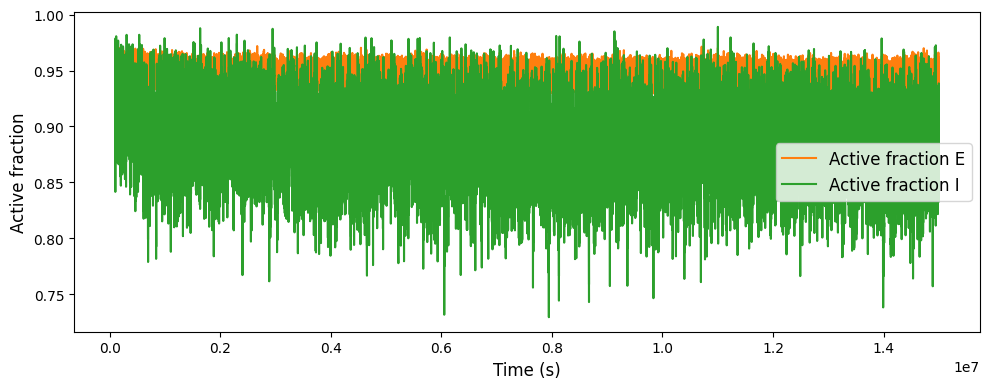

In [3]:
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']

plt.figure(figsize=(10, 4))
plt.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction E')
plt.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction I')
plt.xlabel('Time (s)',fontsize=12)
plt.ylabel('Active fraction',fontsize=12)
plt.legend(loc=5,fontsize=12)
plt.tight_layout()

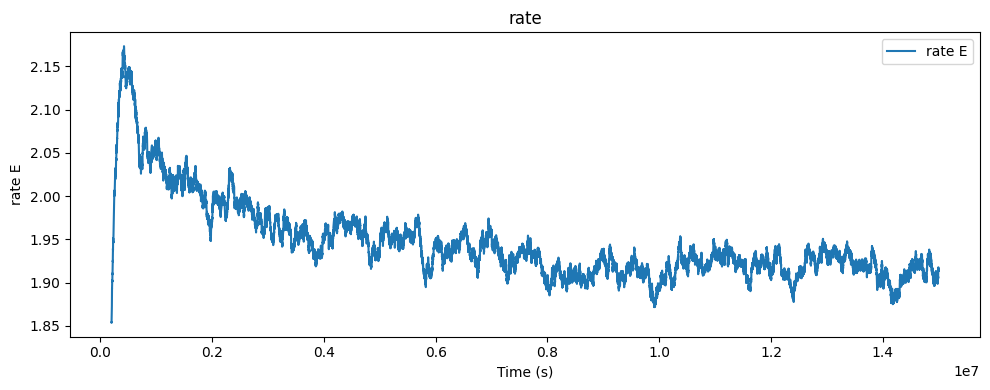

In [4]:
r_est_E = net['rate_pop_mon_E']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[1000:]/ms, r_est_E.r_pop_E[0,1000:]/Hz, color='tab:blue', label='rate E')
plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()

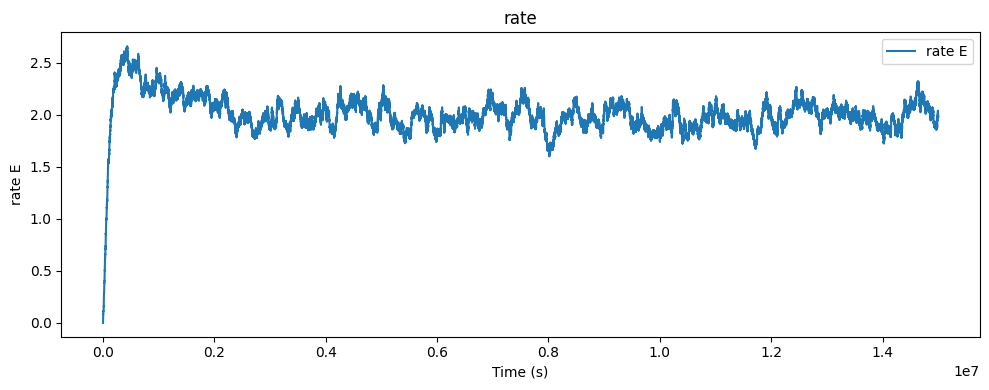

In [5]:
r_est_E = net['r_est']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t/ms, r_est_E.r_est[0]/Hz, color='tab:blue', label='rate E')
plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()

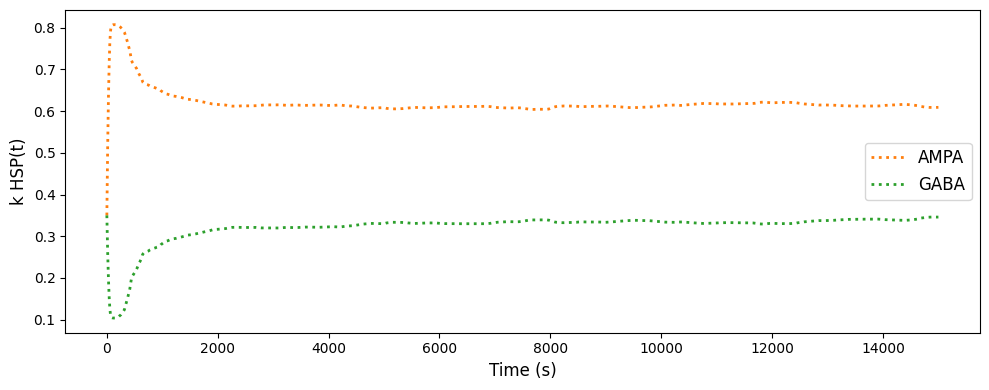

In [6]:
net.restore('baseline', filename='baseline_2hz.bri')
kAMPA_mon_E=net['k_AMPA_E_hsp']
kGABA_mon_E=net['k_GABA_E_hsp']

plt.figure(figsize=(10, 4))
plt.plot(kAMPA_mon_E.t/second, kAMPA_mon_E.k_AMPA_E_hsp[45], label='AMPA',color='tab:orange',linestyle=':',linewidth=2)
plt.plot(kGABA_mon_E.t/second, kGABA_mon_E.k_GABA_E_hsp[45], label='GABA',color='tab:green',linestyle=':',linewidth=2)
plt.xlabel('Time (s)',fontsize=12)
plt.ylabel('k HSP(t)',fontsize=12)
#plt.title('Homeostatic Synaptic Scaling')
plt.legend(loc=5,fontsize=12)
plt.tight_layout()

In [ ]:
#net.store('baseline',filename='baseline_2hz.bri')

In [7]:
import numpy as np, matplotlib.pyplot as plt
import importlib, hsp_capacity, HSP_Phase
importlib.reload(hsp_capacity)
importlib.reload(HSP_Phase)
from HSP_Phase import (characterize_cycle, phase_resolved_capacity,
                       intervention_comparison)

AMP_STAR = 8.0        # from the amplitude calibration
STEP_S   = 0.05

import hsp_metrics, hsp_capacity
print('metrics  :', bool(getattr(hsp_metrics,  '_MODEL_NS', None)))
print('capacity :', bool(getattr(hsp_capacity, '_MODEL_NS', None)))

metrics  : False
capacity : False


In [8]:
import hsp_capacity, HSP_Phase
print(HSP_Phase.capacity_report.__module__)      # 'hsp_capacity'
print(hsp_capacity.capacity_report is HSP_Phase.capacity_report)  # True
import inspect
print('ridges' in inspect.signature(hsp_capacity.capacity_report).parameters)  # True (new)
print('_oof_capacity' in dir(hsp_capacity))      # True (new helper exists)

hsp_capacity
True
True
True


In [15]:
f_seizure = 36.0
drug_dbs = {'dbs': True, 'dbs_freq_hz': 120.0, 'dbs_amp_pA': 30.0}

prc = HSP_Phase.phase_resolved_capacity(net, f_seizure, drug=drug_dbs,
                                        amp_hz=AMP_STAR, step_s=STEP_S, n_steps=2000)
cyc = prc["cycle"]
print(f"bursting={cyc['is_bursting']}  period={cyc['period_s']}  "
      f"recovery={cyc['recovery_s']}  cycle power={cyc['cycle_lf_power']:.3f}")
for r in prc["rows"]:
    if r.get("found"):
        print(f"{r['phase']:12} IPC={r['ipc_total']:.3f}  linMC={r['linear_mc']:.3f}  "
              f"E={r['E_rate']:.2f} I={r['I_rate']:.2f}  kA={r['k_AMPA']:.2f} kG={r['k_GABA']:.2f}")
    else:
        print(f"{r['phase']:12} (not found: {r.get('status')})")

INFO:numexpr.utils:NumExpr defaulting to 16 threads.


bursting=False  period=nan  recovery=nan  cycle power=0.010
steady       IPC=0.143  linMC=0.143  E=1.62 I=1.54  kA=0.91 kG=0.08


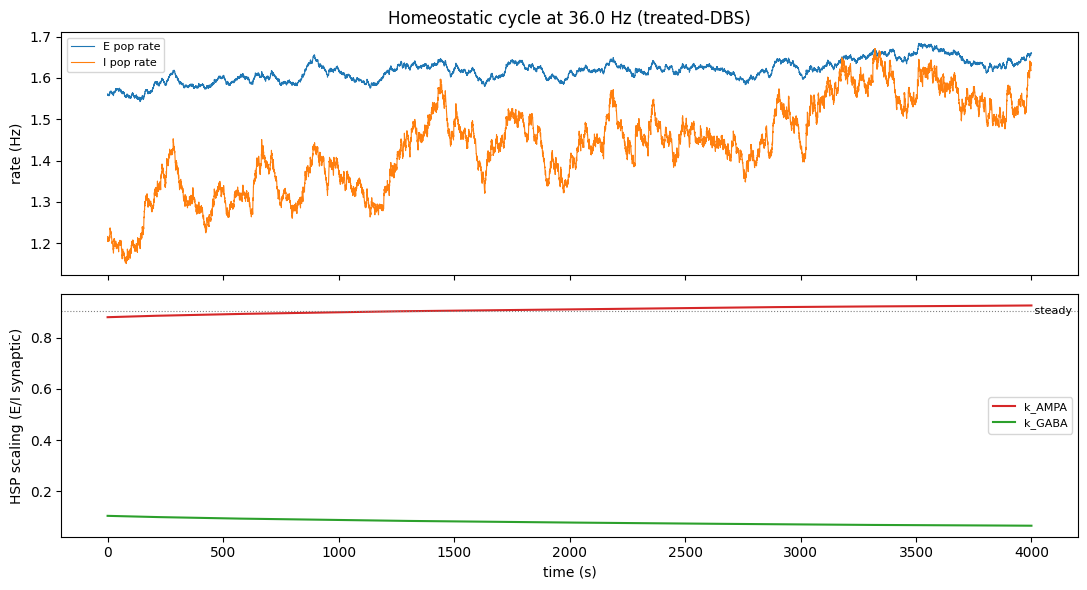

In [17]:
# cycle trace with the three snapshot phases marked on k_AMPA
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(cyc["t"], cyc["rE"], color="tab:blue", lw=.8, label="E pop rate")
ax[0].plot(cyc["t"], cyc["rI"], color="tab:orange", lw=.8, label="I pop rate")
ax[0].set_ylabel("rate (Hz)"); ax[0].legend(fontsize=8); ax[0].set_title(
    f"Homeostatic cycle at {f_seizure} Hz (treated-DBS)")
ax[1].plot(cyc["t"], cyc["k_AMPA"], color="tab:red", label="k_AMPA")
ax[1].plot(cyc["t"], cyc["k_GABA"], color="tab:green", label="k_GABA")
for r in prc["rows"]:
    if r.get("found"):
        ax[1].axhline(r["k_target"], ls=":", color="0.5", lw=.8)
        ax[1].text(cyc["t"][-1], r["k_target"], " "+r["phase"], fontsize=8, va="center")
ax[1].set_ylabel("HSP scaling (E/I synaptic)"); ax[1].set_xlabel("time (s)")
ax[1].legend(fontsize=8); fig.tight_layout(); plt.show()

# DBS intervention — capacity vs seizure trade-off

Deep-brain-stimulation-like therapy modeled as a **second Poisson source injecting a small current** into the excitatory population (current-based, one-to-one onto E cells; off unless applied). Clinical DBS is ~120 Hz; here it raises baseline activity and adds an uncontrolled input.

**Mechanistic prediction.** Because the DBS current is independent of the probe stream `u`, during the probe it is exactly Dambre's *noise input* `v`: the reservoir spends capacity representing `v`, but the readout only regresses on `u`, so measured IPC carries a cost benzo did not impose.

Two opposite therapy signatures:
- **Benzo**: suppresses seizure, IPC *up* (inhibition decorrelates, no noise added).
- **DBS**: suppresses seizure, IPC pays a *noise-to-signal* cost — likely **below the 40 Hz fixed point** even when it restores ~2 Hz firing.

**Prerequisites** (model cell + `HSP_Phase`): `I_dbs` current in `eqs_E`, `tau_dbs` constant, `pg_dbs`/`C_DBS_E` built off, baseline **regenerated** with DBS present-and-off, and the `dbs` branch in `_apply_drugs`. This notebook assumes `net` is that rebuilt network with a fresh `baseline_2hz.bri`.

> All drug comparisons are at **36 Hz**; the 40 Hz steady state is an **unpaired reference** (different operating point), not a paired endpoint.

In [9]:
import importlib, numpy as np, matplotlib.pyplot as plt
import hsp_capacity, HSP_Phase
importlib.reload(hsp_capacity); importlib.reload(HSP_Phase)   # leaf first

AMP_STAR = 8.0
STEP_S   = 0.05
seeds    = [11, 22, 33, 44, 55, 66, 77, 88, 99, 111]   # 10 paired input seeds

DBS_FREQ_HZ = 120.0
DBS_AMP_PA  = 30.0     # starting current weight (SWEEP in last cell)

## 1. Single-seed look at the 36 Hz DBS cycle
Does DBS abolish the bursting (collapse to a stabilized state)? Same layout as the benzo trace cell.

bursting=False  period=nan  recovery=nan  cycle power=0.011
phase           IPC  linMC  multiI     E     I   E/I    kA    kG stable
steady        0.107  0.086   0.160  1.61  1.33  1.21  0.91  0.08  False


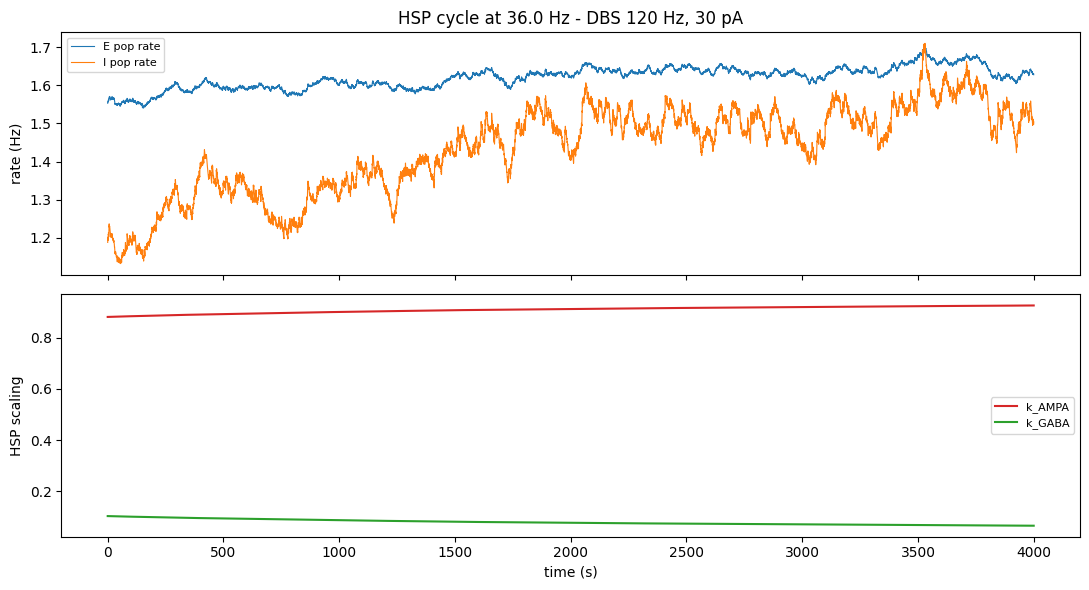

In [19]:
f_seizure = 36.0
drug_dbs = {'dbs': True, 'dbs_freq_hz': DBS_FREQ_HZ, 'dbs_amp_pA': DBS_AMP_PA}

prc = HSP_Phase.phase_resolved_capacity(net, f_seizure, drug=drug_dbs,
                                        amp_hz=AMP_STAR, step_s=STEP_S, n_steps=2000)
cyc = prc["cycle"]
print(f"bursting={cyc['is_bursting']}  period={cyc['period_s']}  "
      f"recovery={cyc['recovery_s']}  cycle power={cyc['cycle_lf_power']:.3f}")
print(f"{'phase':12}{'IPC':>7}{'linMC':>7}{'multiI':>8}{'E':>6}{'I':>6}"
      f"{'E/I':>6}{'kA':>6}{'kG':>6}{'stable':>7}")
for r in prc["rows"]:
    if not r.get("found"):
        print(f"{r['phase']:12} (not found: {r.get('status')})"); continue
    print(f"{r['phase']:12}{r['ipc_total']:7.3f}{r['linear_mc']:7.3f}"
          f"{r['multi_information']:8.3f}{r['E_rate']:6.2f}{r['I_rate']:6.2f}"
          f"{r['EI_ratio']:6.2f}{r['k_AMPA']:6.2f}{r['k_GABA']:6.2f}"
          f"{str(not r['burst_during_probe']):>7}")

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(cyc["t"], cyc["rE"], color="tab:blue", lw=.8, label="E pop rate")
ax[0].plot(cyc["t"], cyc["rI"], color="tab:orange", lw=.8, label="I pop rate")
ax[0].set_ylabel("rate (Hz)"); ax[0].legend(fontsize=8)
ax[0].set_title(f"HSP cycle at {f_seizure} Hz - DBS {DBS_FREQ_HZ:.0f} Hz, {DBS_AMP_PA:.0f} pA")
ax[1].plot(cyc["t"], cyc["k_AMPA"], color="tab:red", label="k_AMPA")
ax[1].plot(cyc["t"], cyc["k_GABA"], color="tab:green", label="k_GABA")
ax[1].set_ylabel("HSP scaling"); ax[1].set_xlabel("time (s)"); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 2. Seeded replication: control vs DBS (paired, 36 Hz) + 40 Hz reference
Same seeds for both. Control = no drug. If DBS abolishes bursting, its 36 Hz run collapses to a single `steady`-labeled state (the collapse *is* the seizure-suppression result).

In [20]:
res_ctrl = HSP_Phase.run_phase_replication(net, seeds,
                                           burst_freq_hz=36.0, steady_freq_hz=40.0)
res_dbs  = HSP_Phase.run_phase_replication(net, seeds,
                                           burst_freq_hz=36.0, steady_freq_hz=40.0,
                                           drug=drug_dbs)

merged = {f"ctrl_{k}": v for k, v in res_ctrl["by_phase"].items()}
merged.update({f"dbs_{k}":  v for k, v in res_dbs["by_phase"].items()})
print("control states :", [k for k,v in res_ctrl["by_phase"].items() if v.get("found")])
print("DBS states     :", [k for k,v in res_dbs["by_phase"].items()  if v.get("found")])

control states : ['post_ictal', 'mid', 'pre_ictal', 'steady']
DBS states     : ['steady']


In [21]:
dbs_key = "dbs_steady" if "dbs_steady" in merged else "dbs_mid"   # collapsed vs reshaped
st = HSP_Phase.paired_phase_stats(merged, metric="ipc_total",
                                  contrasts=[(dbs_key, "ctrl_mid")])
for ph, s in st["per_phase"].items():
    print(f"{ph:16s} IPC {s['mean']:.3f}  SD {s['sd']:.3f}  "
          f"95%CI [{s['lo']:.3f},{s['hi']:.3f}]  n={s['n']}")
print()
for nm, c in st["contrasts"].items():
    print(f"{nm:26s} d {c['mean_diff']:+.3f}  95%CI [{c['lo']:+.3f},{c['hi']:+.3f}]"
          f"  p_w={c['p_wilcoxon']:.3f}")

ctrl_post_ictal  IPC 0.080  SD 0.016  95%CI [0.068,0.092]  n=10
ctrl_mid         IPC 0.106  SD 0.022  95%CI [0.089,0.122]  n=10
ctrl_pre_ictal   IPC 0.148  SD 0.020  95%CI [0.134,0.163]  n=10
ctrl_steady      IPC 0.141  SD 0.021  95%CI [0.126,0.156]  n=10
dbs_steady       IPC 0.076  SD 0.091  95%CI [0.011,0.141]  n=10

dbs_steady-ctrl_mid        d -0.030  95%CI [-0.094,+0.035]  p_w=0.232


## 3. Three-point comparison
`36 Hz interictal (untreated)` -> `36 Hz DBS` (paired slope), with `40 Hz steady` as an unpaired reference. Expect DBS below steady even if firing is restored to ~2 Hz.

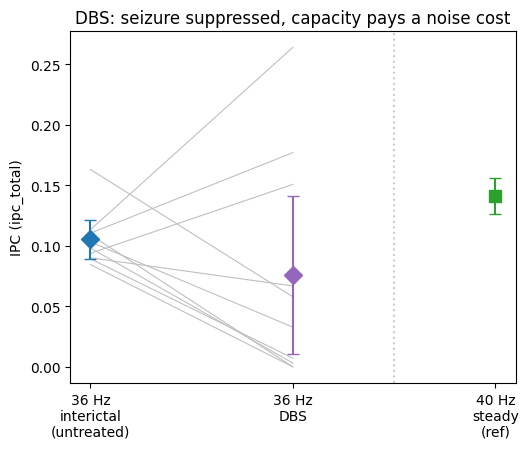

In [22]:
from scipy import stats
a = np.asarray(merged["ctrl_mid"]["ipc_total"], float)     # 36 Hz interictal
b = np.asarray(merged[dbs_key]["ipc_total"], float)        # 36 Hz DBS (paired)
s = np.asarray(merged["ctrl_steady"]["ipc_total"], float)  # 40 Hz steady (ref)

def mci(x):
    n=len(x); m=x.mean(); h=stats.t.ppf(.975,n-1)*x.std(ddof=1)/np.sqrt(n); return m,h

fig, ax = plt.subplots(figsize=(5.4, 4.6))
for ai, bi in zip(a, b):
    ax.plot([0,1],[ai,bi], color='0.75', lw=.8, zorder=1)
for x,arr,col in [(0,a,'tab:blue'),(1,b,'tab:purple')]:
    m,h = mci(arr); ax.errorbar(x,m,yerr=h,fmt='D',color=col,ms=9,capsize=4,zorder=3)
m,h = mci(s); ax.errorbar(2.0,m,yerr=h,fmt='s',color='tab:green',ms=9,capsize=4)
ax.axvline(1.5, ls=':', color='0.8')
ax.set_xticks([0,1,2])
ax.set_xticklabels(["36 Hz\ninterictal\n(untreated)","36 Hz\nDBS","40 Hz\nsteady\n(ref)"])
ax.set_ylabel("IPC (ipc_total)")
ax.set_title("DBS: seizure suppressed, capacity pays a noise cost")
plt.tight_layout(); plt.show()

## 4. Rate-matched check (the rigorous point)
DBS may restore ~2 Hz firing yet still carry less `u`-information than the 40 Hz fixed point. If E-rates coincide but DBS IPC < steady IPC, that isolates the noise-to-signal cost from any rate difference. (E-rate here is read from the cycle characterization, since the lean probe doesn't store it.)

In [23]:
def cyc_erate(res, cond):
    st = res.get(cond, {}).get("cycle", {})
    return st.get("E_rate", np.nan)

ipc_dbs    = float(np.mean(merged[dbs_key]["ipc_total"]))
ipc_steady = float(np.mean(merged["ctrl_steady"]["ipc_total"]))
er_dbs     = cyc_erate(res_dbs, "steady") if "steady" in res_dbs else cyc_erate(res_dbs, "burst")
er_steady  = cyc_erate(res_ctrl, "steady")

print(f"DBS 36Hz    : IPC={ipc_dbs:.3f}   E_rate(cycle)={er_dbs:.2f} Hz")
print(f"steady 40Hz : IPC={ipc_steady:.3f}   E_rate(cycle)={er_steady:.2f} Hz")
print("\nClose E-rates + (DBS IPC < steady IPC)  ->  rate-matched capacity gap = the noise cost.")

DBS 36Hz    : IPC=0.076   E_rate(cycle)=2.10 Hz
steady 40Hz : IPC=0.141   E_rate(cycle)=1.91 Hz

Close E-rates + (DBS IPC < steady IPC)  ->  rate-matched capacity gap = the noise cost.


## 5. Amplitude sweep — the DBS arm of the trade-off (optional; one full run per amplitude)
Seizure suppression (`cycle_lf_power`) and IPC vs DBS current. Keep the list short — each entry is a full cycle+snapshot run. Uses fewer seeds to stay cheap.

amp=  0.0 pA  power= 22.116  IPC=0.141 ± 0.015  (steady)
amp=  5.0 pA  power= 34.859  IPC=0.114 ± 0.013  (mid)
amp= 10.0 pA  power= 16.443  IPC=0.110 ± 0.011  (mid)
amp= 15.0 pA  power= 14.369  IPC=0.107 ± 0.011  (mid)
amp= 20.0 pA  power= 13.345  IPC=0.105 ± 0.017  (mid)
amp= 25.0 pA  power= 10.320  IPC=0.111 ± 0.017  (mid)
amp= 30.0 pA  power=  0.009  IPC=0.061 ± 0.059  (steady)
amp= 40.0 pA  power=  0.008  IPC=0.177 ± 0.015  (steady)


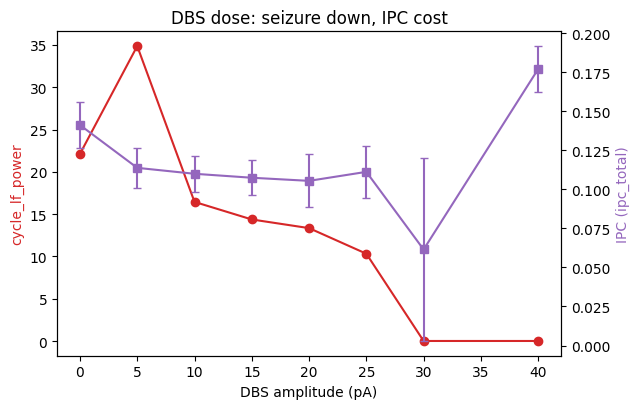

In [25]:
amps = [0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 40.0]
sweep = []
for amp in amps:
    d = {} if amp == 0 else {'dbs': True, 'dbs_freq_hz': DBS_FREQ_HZ, 'dbs_amp_pA': amp}
    r = HSP_Phase.run_phase_replication(net, seeds,          # ALL 10 seeds
                                        burst_freq_hz=36.0, steady_freq_hz=40.0, drug=d)
    bp = r["by_phase"]
    key = "steady" if bp.get("steady", {}).get("found") else "mid"
    if not bp.get(key, {}).get("found"):
        print(f"amp={amp}: NO STATE FOUND -> states={[k for k,v in bp.items() if v.get('found')]}"
              f"  bursting={r['burst']['cycle']['is_bursting']}")
        sweep.append((amp, r["burst"]["cycle"]["cycle_lf_power"], np.nan, np.nan)); continue
    ipc = np.asarray(bp[key]["ipc_total"], float)
    sem = ipc.std(ddof=1)/np.sqrt(len(ipc))
    ci  = stats.t.ppf(.975, len(ipc)-1) * sem
    power = r["burst"]["cycle"]["cycle_lf_power"]
    sweep.append((amp, power, ipc.mean(), ci))
    print(f"amp={amp:5.1f} pA  power={power:7.3f}  IPC={ipc.mean():.3f} ± {ci:.3f}  ({key})")

sweep = np.array(sweep)
fig, ax1 = plt.subplots(figsize=(6.5, 4.2))
ax1.plot(sweep[:,0], sweep[:,1], 'o-', color='tab:red')
ax1.set_xlabel('DBS amplitude (pA)'); ax1.set_ylabel('cycle_lf_power', color='tab:red')
ax2 = ax1.twinx()
ax2.errorbar(sweep[:,0], sweep[:,2], yerr=sweep[:,3], fmt='s-', color='tab:purple', capsize=3)
ax2.set_ylabel('IPC (ipc_total)', color='tab:purple')
ax1.set_title('DBS dose: seizure down, IPC cost'); fig.tight_layout(); plt.show()

In [28]:
# ONCE, outside the loop
ref = HSP_Phase.phase_capacity_seeded(net, 40.0, seeds)          # untreated 40 Hz
ipc_ref = np.mean(ref["by_phase"]["steady"]["ipc_total"])
amps = [0.0, 5.0, 10.0, 20.0, 25.0, 30.0, 40.0]
sweep = []
# the sweep: 36 Hz ONLY
for amp in amps:
    d = {} if amp == 0 else {'dbs': True, 'dbs_freq_hz': DBS_FREQ_HZ, 'dbs_amp_pA': amp}
    r36 = HSP_Phase.phase_capacity_seeded(net, 36.0, seeds, drug=d, phases=("mid",))   # <- one freq
    bp = r36["by_phase"]
    key = "mid" if bp.get("mid", {}).get("found") else "steady"
    ipc = np.asarray(bp[key]["ipc_total"], float)
    power = r36["cycle"]["cycle_lf_power"]

amp=  0.0 pA  power=  34.508  IPC=0.099 ± 0.016  (mid)
amp=  5.0 pA  power=  34.859  IPC=0.114 ± 0.011  (mid)
amp= 10.0 pA  power=  22.058  IPC=0.117 ± 0.014  (mid)
amp= 20.0 pA  power=  12.631  IPC=0.111 ± 0.014  (mid)
amp= 25.0 pA  power=   9.909  IPC=0.111 ± 0.019  (mid)
amp= 30.0 pA  power=   0.011  IPC=0.076 ± 0.065  (steady)
amp= 40.0 pA  power=   0.009  IPC=0.181 ± 0.016  (steady)


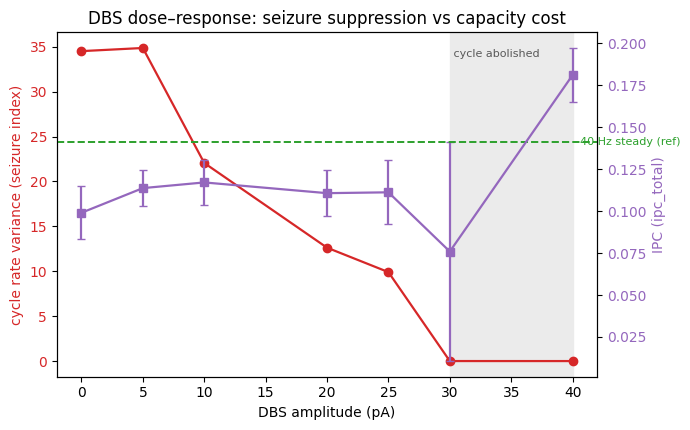

In [29]:
import numpy as np, matplotlib.pyplot as plt
from scipy import stats

# ONCE, outside the loop
ref = HSP_Phase.phase_capacity_seeded(net, 40.0, seeds)          # untreated 40 Hz
ipc_ref = float(np.mean(ref["by_phase"]["steady"]["ipc_total"]))

amps = [0.0, 5.0, 10.0, 20.0, 25.0, 30.0, 40.0]
sweep = []

for amp in amps:
    d = {} if amp == 0 else {'dbs': True, 'dbs_freq_hz': DBS_FREQ_HZ, 'dbs_amp_pA': amp}
    r36 = HSP_Phase.phase_capacity_seeded(net, 36.0, seeds, drug=d, phases=("mid",))
    bp = r36["by_phase"]
    key = "mid" if bp.get("mid", {}).get("found") else "steady"
    if not bp.get(key, {}).get("found"):
        print(f"amp={amp:5.1f} pA  NO STATE FOUND")
        sweep.append((amp, r36["cycle"]["cycle_lf_power"], np.nan, np.nan, 0))
        continue
    ipc   = np.asarray(bp[key]["ipc_total"], float)
    power = r36["cycle"]["cycle_lf_power"]
    n     = len(ipc)
    ci    = stats.t.ppf(.975, n-1) * ipc.std(ddof=1) / np.sqrt(n)
    suppressed = int(key == "steady")          # 1 = cycle abolished
    sweep.append((amp, power, ipc.mean(), ci, suppressed))
    print(f"amp={amp:5.1f} pA  power={power:8.3f}  IPC={ipc.mean():.3f} ± {ci:.3f}  ({key})")

sweep = np.array(sweep, float)
a, pw, ipc_m, ipc_ci, supp = sweep.T

fig, ax1 = plt.subplots(figsize=(7, 4.4))

# seizure axis (left)
ax1.plot(a, pw, 'o-', color='tab:red', lw=1.6, label='seizure (cycle power)')
ax1.set_xlabel('DBS amplitude (pA)')
ax1.set_ylabel('cycle rate variance (seizure index)', color='tab:red')
ax1.tick_params(axis='y', labelcolor='tab:red')

# capacity axis (right)
ax2 = ax1.twinx()
ax2.errorbar(a, ipc_m, yerr=ipc_ci, fmt='s-', color='tab:purple',
             lw=1.6, capsize=3, label='IPC (36 Hz)')
ax2.axhline(ipc_ref, ls='--', color='tab:green', lw=1.4)
ax2.text(a[-1], ipc_ref, '  40 Hz steady (ref)', color='tab:green',
         va='center', fontsize=8)
ax2.set_ylabel('IPC (ipc_total)', color='tab:purple')
ax2.tick_params(axis='y', labelcolor='tab:purple')

# mark where the cycle is abolished
onset = a[supp == 1]
if onset.size:
    ax1.axvspan(onset.min(), a.max(), color='0.92', zorder=0)
    ax1.text(onset.min(), ax1.get_ylim()[1]*0.95, ' cycle abolished',
             fontsize=8, color='0.35', va='top')

ax1.set_title('DBS dose–response: seizure suppression vs capacity cost')
fig.tight_layout(); plt.show()

amp=  0.0 pA  power=  34.508  PR=92.12 ± 0.25  (mid)
amp=  5.0 pA  power=  34.859  PR=91.57 ± 0.29  (mid)
amp= 10.0 pA  power=  22.058  PR=91.65 ± 0.30  (mid)
amp= 20.0 pA  power=  12.631  PR=92.10 ± 0.25  (mid)
amp= 25.0 pA  power=   9.909  PR=91.67 ± 0.28  (mid)
amp= 30.0 pA  power=   0.011  PR=25.66 ± 28.39  (steady)
amp= 40.0 pA  power=   0.009  PR=85.58 ± 0.80  (steady)


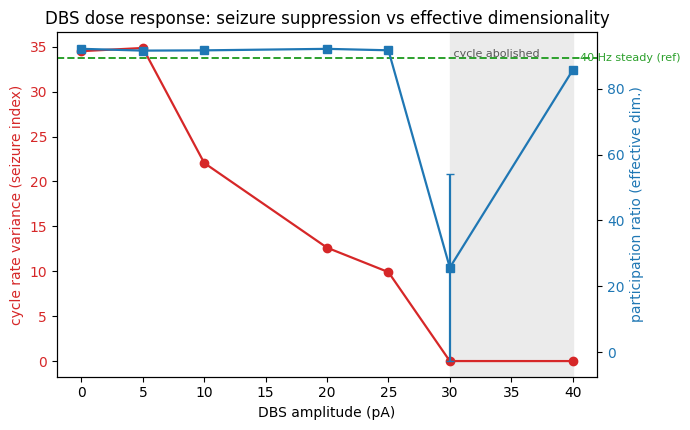

In [39]:
import numpy as np, matplotlib.pyplot as plt
from scipy import stats

# ONCE, outside the loop
ref = HSP_Phase.phase_capacity_seeded(net, 40.0, seeds)
pr_ref = float(np.mean(ref["by_phase"]["steady"]["participation_ratio"]))

amps = [0.0, 5.0, 10.0, 20.0, 25.0, 30.0, 40.0]
sweep = []

for amp in amps:
    d = {} if amp == 0 else {'dbs': True, 'dbs_freq_hz': DBS_FREQ_HZ, 'dbs_amp_pA': amp}
    r36 = HSP_Phase.phase_capacity_seeded(net, 36.0, seeds, drug=d, phases=("mid",))
    bp = r36["by_phase"]
    key = "mid" if bp.get("mid", {}).get("found") else "steady"
    if not bp.get(key, {}).get("found"):
        print(f"amp={amp:5.1f} pA  NO STATE FOUND")
        sweep.append((amp, r36["cycle"]["cycle_lf_power"], np.nan, np.nan, 0))
        continue
    pr    = np.asarray(bp[key]["participation_ratio"], float)
    power = r36["cycle"]["cycle_lf_power"]
    n     = len(pr)
    ci    = stats.t.ppf(.975, n-1) * pr.std(ddof=1) / np.sqrt(n)
    suppressed = int(key == "steady")
    sweep.append((amp, power, pr.mean(), ci, suppressed))
    print(f"amp={amp:5.1f} pA  power={power:8.3f}  PR={pr.mean():.2f} ± {ci:.2f}  ({key})")

sweep = np.array(sweep, float)
a, pw, pr_m, pr_ci, supp = sweep.T

fig, ax1 = plt.subplots(figsize=(7, 4.4))

ax1.plot(a, pw, 'o-', color='tab:red', lw=1.6)
ax1.set_xlabel('DBS amplitude (pA)')
ax1.set_ylabel('cycle rate variance (seizure index)', color='tab:red')
ax1.tick_params(axis='y', labelcolor='tab:red')

ax2 = ax1.twinx()
ax2.errorbar(a, pr_m, yerr=pr_ci, fmt='s-', color='tab:blue',
             lw=1.6, capsize=3, label='PR (36 Hz)')
ax2.axhline(pr_ref, ls='--', color='tab:green', lw=1.4)
ax2.text(a[-1], pr_ref, '  40 Hz steady (ref)', color='tab:green',
         va='center', fontsize=8)
ax2.set_ylabel('participation ratio (effective dim.)', color='tab:blue')
ax2.tick_params(axis='y', labelcolor='tab:blue')

onset = a[supp == 1]
if onset.size:
    ax1.axvspan(onset.min(), a.max(), color='0.92', zorder=0)
    ax1.text(onset.min(), ax1.get_ylim()[1]*0.95, ' cycle abolished',
             fontsize=8, color='0.35', va='top')

ax1.set_title('DBS dose response: seizure suppression vs effective dimensionality')
fig.tight_layout(); plt.show()

In [5]:
import os, pickle, numpy as np
os.makedirs('results/dbs_sweep', exist_ok=True)

def sweep_one(amp):
    """Run one amplitude, cache to disk, skip if already done."""
    path = f'results/dbs_sweep/amp_{amp:g}.pkl'
    if os.path.exists(path):                       # resume: skip completed
        with open(path, 'rb') as f:
            return pickle.load(f)
    d = {} if amp == 0 else {'dbs': True, 'dbs_freq_hz': DBS_FREQ_HZ, 'dbs_amp_pA': amp}
    r36 = HSP_Phase.phase_capacity_seeded(net, 36.0, seeds, drug=d, phases=("mid",))
    bp = r36["by_phase"]
    key = "mid" if bp.get("mid", {}).get("found") else "steady"
    rec = dict(amp=amp, power=r36["cycle"]["cycle_lf_power"], key=key,
               found=bool(bp.get(key, {}).get("found")),
               ipc_total=np.asarray(bp[key]["ipc_total"], float),
               participation_ratio=np.asarray(bp[key]["participation_ratio"], float),
               E_rate_probe=np.asarray(bp[key]["E_rate_probe"], float),
               burst_during_probe=np.asarray(bp[key]["burst_during_probe"], bool),
               seeds=list(seeds))
    with open(path, 'wb') as f:                    # save IMMEDIATELY, per amplitude
        pickle.dump(rec, f)
    print(f"amp={amp:5.1f} pA  power={rec['power']:8.3f}  "
          f"IPC={rec['ipc_total'].mean():.3f}  ({key})  [saved]")
    return rec

# amps = [0.0, 5.0, 10.0, 20.0, 25.0, 30.0, 40.0]
# sweep = [sweep_one(a) for a in amps]

In [12]:
res_ctrl  = HSP_Phase.run_phase_replication(net, seeds, burst_freq_hz=36.0,
                                            steady_freq_hz=40.0)
res_benzo = HSP_Phase.run_phase_replication(net, seeds, burst_freq_hz=36.0,
                                            steady_freq_hz=40.0,
                                            drug={'benzo': True, 'benzo_kGABA': 1.0})

### save res_ctrl and benzo

In [ ]:
# import pickle, os
# os.makedirs('results', exist_ok=True)

# with open('results/res_ctrl.pkl', 'wb') as f:
#     pickle.dump(res_ctrl, f)
# with open('results/res_benzo.pkl', 'wb') as f:
#     pickle.dump(res_benzo, f)

# print("saved:", os.path.getsize('results/res_ctrl.pkl')//1024, "KB /",
#                 os.path.getsize('results/res_benzo.pkl')//1024, "KB")

saved: 1880 KB / 1878 KB


In [7]:
print('E_rate_probe' in res_ctrl['by_phase']['steady'])   # should be True
print('E_rate_probe' in res_benzo['by_phase']['steady'])  # should be True

True
True


### load res_ctrl and res_benzo

In [ ]:
DBS_FREQ_HZ = 120.0
seeds = [11, 22, 33, 44, 55, 66, 77, 88, 99, 111]
import pickle
res_ctrl  = pickle.load(open('results/res_ctrl.pkl','rb'))
res_benzo = pickle.load(open('results/res_benzo.pkl','rb'))

In [6]:
import pickle
with open('results/res_ctrl.pkl', 'rb') as f:  res_ctrl  = pickle.load(f)
with open('results/res_benzo.pkl', 'rb') as f: res_benzo = pickle.load(f)

amp= 45.0 pA  power=   0.008  IPC=0.170  (steady)  [saved]
amp= 50.0 pA  power=   0.008  IPC=0.166  (steady)  [saved]
amp= 55.0 pA  power=   0.008  IPC=0.169  (steady)  [saved]
amp= 60.0 pA  power=   0.007  IPC=0.163  (steady)  [saved]
DBS 0pA        rate=  1.07  IPC=0.099  PR= 92.1  bursting 0/10
DBS 5pA        rate=  1.18  IPC=0.114  PR= 91.6  bursting 0/10
DBS 10pA       rate=  1.22  IPC=0.117  PR= 91.6  bursting 0/10
DBS 20pA       rate=  1.24  IPC=0.111  PR= 92.1  bursting 0/10
DBS 25pA       rate=  1.29  IPC=0.108  PR= 92.1  bursting 0/10
DBS 30pA       rate=  1.77  IPC=0.197  PR= 83.1  bursting 7/10
DBS 40pA       rate=  1.86  IPC=0.181  PR= 85.6  bursting 0/10
DBS 45pA       rate=  1.89  IPC=0.170  PR= 86.8  bursting 0/10
DBS 50pA       rate=  1.93  IPC=0.166  PR= 87.4  bursting 0/10
DBS 55pA       rate=  1.98  IPC=0.169  PR= 87.9  bursting 0/10
DBS 60pA       rate=  2.03  IPC=0.163  PR= 88.3  bursting 0/10
ctrl post_ictal rate=  0.96  IPC=0.079  PR= 92.8  bursting 0/10
ctrl mi

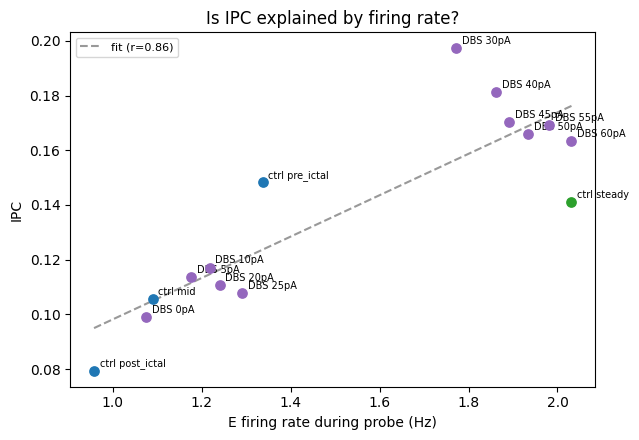


DBS 40pA: IPC=0.181, rate-predicted=0.163, residual=+0.018


In [12]:
import numpy as np, matplotlib.pyplot as plt
from scipy import stats
amps = [0.0, 5.0, 10.0, 20.0, 25.0, 30.0, 40.0, 45.0, 50.0, 55.0, 60.0]
def _get(d, *names):
    """First present key among names, else None."""
    for n in names:
        if n in d: return np.asarray(d[n])
    return None

conds = []
for amp in amps:
    r = sweep_one(amp)
    if r.get('found'):
        conds.append((f'DBS {amp:g}pA', r))
for k in ('post_ictal','mid','pre_ictal','steady'):
    e = res_ctrl['by_phase'].get(k, {})
    if e.get('found'):
        conds.append((f'ctrl {k}', e))

rows = []
for lbl, d in conds:
    ipc  = _get(d, 'ipc_total', 'ipc')
    pr   = _get(d, 'participation_ratio', 'pr')
    rate = _get(d, 'E_rate_probe')                       # may be None
    burst= _get(d, 'burst_during_probe')
    if ipc is None:
        print(f"{lbl:14s} no IPC - skipped"); continue
    ipc = ipc.astype(float)
    burst = burst.astype(bool) if burst is not None else np.zeros(len(ipc), bool)
    keep = ~burst
    if keep.sum() == 0:
        print(f"{lbl:14s} ALL {len(ipc)} probes bursting - excluded"); continue
    rate_m = float(rate.astype(float)[keep].mean()) if rate is not None else np.nan
    pr_m   = float(pr.astype(float)[keep].mean())   if pr   is not None else np.nan
    rows.append(dict(label=lbl, n=len(ipc), n_burst=int(burst.sum()),
                     ipc=float(ipc[keep].mean()), rate=rate_m, pr=pr_m,
                     ipc_all=ipc, keep=keep))
    tag = "" if rate is not None else "  (no rate)"
    print(f"{lbl:14s} rate={rate_m:6.2f}  IPC={rows[-1]['ipc']:.3f}  "
          f"PR={pr_m:5.1f}  bursting {int((~keep).sum())}/{len(ipc)}{tag}")

# regression only over conditions that actually have a rate
R = np.array([r['rate'] for r in rows])
I = np.array([r['ipc']  for r in rows])
ok = np.isfinite(R) & np.isfinite(I)
if ok.sum() < 3:
    print(f"\nOnly {ok.sum()} conditions have E_rate_probe - not enough for a rate "
          f"regression. Re-run the conditions you need with the E_rate_probe patch.")
else:
    sl, ic, rr, pp, se = stats.linregress(R[ok], I[ok])
    print(f"\nIPC ~ E_rate:  slope={sl:+.4f}  r={rr:.2f}  p={pp:.3f}  (n={ok.sum()})")

    fig, ax = plt.subplots(figsize=(6.5,4.5))
    xs = np.linspace(R[ok].min(), R[ok].max(), 50)
    ax.plot(xs, ic + sl*xs, '--', color='0.6', label=f'fit (r={rr:.2f})')
    for r in rows:
        if not np.isfinite(r['rate']): continue
        c = 'tab:green' if r['label']=='ctrl steady' else \
            ('tab:purple' if r['label'].startswith('DBS') else 'tab:blue')
        ax.scatter(r['rate'], r['ipc'], color=c, s=45, zorder=3)
        ax.annotate(r['label'], (r['rate'], r['ipc']), fontsize=7,
                    xytext=(4,3), textcoords='offset points')
    ax.set_xlabel('E firing rate during probe (Hz)'); ax.set_ylabel('IPC')
    ax.set_title('Is IPC explained by firing rate?'); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

    d40 = next((r for r in rows if r['label'].startswith('DBS 40')), None)
    if d40 and np.isfinite(d40['rate']):
        pred = ic + sl*d40['rate']
        print(f"\nDBS 40pA: IPC={d40['ipc']:.3f}, rate-predicted={pred:.3f}, "
              f"residual={d40['ipc']-pred:+.3f}")

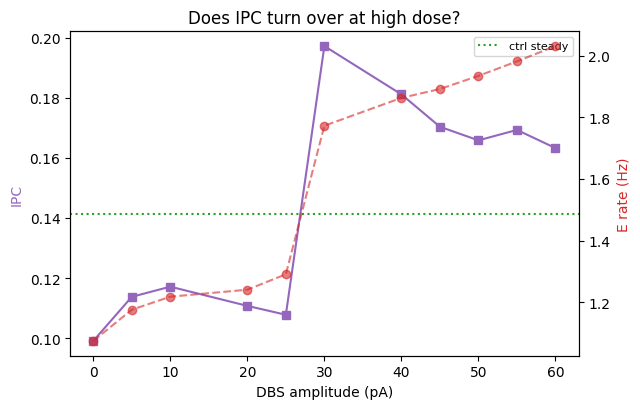

In [13]:
# after the rate plot, add IPC & PR vs amplitude for the DBS points only
dbs = [r for r in rows if r['label'].startswith('DBS') and np.isfinite(r['rate'])]
dbs.sort(key=lambda r: float(r['label'].split()[1][:-2]))   # sort by amplitude
amp_x = [float(r['label'].split()[1][:-2]) for r in dbs]
fig, ax1 = plt.subplots(figsize=(6.5,4.2))
ax1.plot(amp_x, [r['ipc'] for r in dbs], 's-', color='tab:purple')
ax1.set_xlabel('DBS amplitude (pA)'); ax1.set_ylabel('IPC', color='tab:purple')
ax2 = ax1.twinx()
ax2.plot(amp_x, [r['rate'] for r in dbs], 'o--', color='tab:red', alpha=.6)
ax2.set_ylabel('E rate (Hz)', color='tab:red')
ax1.axhline(next(r['ipc'] for r in rows if r['label']=='ctrl steady'),
            ls=':', color='tab:green', label='ctrl steady')
ax1.set_title('Does IPC turn over at high dose?'); ax1.legend(fontsize=8)
plt.tight_layout(); plt.show()

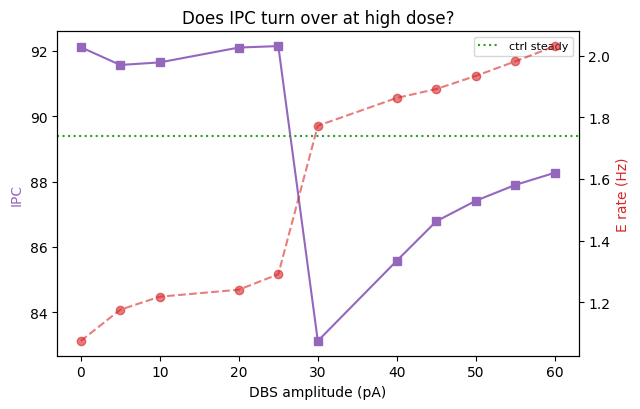

In [14]:
# after the rate plot, add IPC & PR vs amplitude for the DBS points only
dbs = [r for r in rows if r['label'].startswith('DBS') and np.isfinite(r['rate'])]
dbs.sort(key=lambda r: float(r['label'].split()[1][:-2]))   # sort by amplitude
amp_x = [float(r['label'].split()[1][:-2]) for r in dbs]
fig, ax1 = plt.subplots(figsize=(6.5,4.2))
ax1.plot(amp_x, [r['pr'] for r in dbs], 's-', color='tab:purple')
ax1.set_xlabel('DBS amplitude (pA)'); ax1.set_ylabel('IPC', color='tab:purple')
ax2 = ax1.twinx()
ax2.plot(amp_x, [r['rate'] for r in dbs], 'o--', color='tab:red', alpha=.6)
ax2.set_ylabel('E rate (Hz)', color='tab:red')
ax1.axhline(next(r['pr'] for r in rows if r['label']=='ctrl steady'),
            ls=':', color='tab:green', label='ctrl steady')
ax1.set_title('Does IPC turn over at high dose?'); ax1.legend(fontsize=8)
plt.tight_layout(); plt.show()

DBS 0pA        rate=  1.07  IPC=0.099  PR= 92.1  bursting 0/10
DBS 5pA        rate=  1.18  IPC=0.114  PR= 91.6  bursting 0/10
DBS 10pA       rate=  1.22  IPC=0.117  PR= 91.6  bursting 0/10
DBS 20pA       rate=  1.24  IPC=0.111  PR= 92.1  bursting 0/10
DBS 25pA       rate=  1.29  IPC=0.108  PR= 92.1  bursting 0/10
DBS 30pA       rate=  1.77  IPC=0.197  PR= 83.1  bursting 7/10
DBS 40pA       rate=  1.86  IPC=0.181  PR= 85.6  bursting 0/10
ctrl post_ictal rate=  0.96  IPC=0.079  PR= 92.8  bursting 0/10
ctrl mid       rate=  1.09  IPC=0.106  PR= 92.0  bursting 0/10
ctrl pre_ictal rate=  1.34  IPC=0.148  PR= 87.4  bursting 0/10
ctrl steady    rate=  2.03  IPC=0.141  PR= 89.4  bursting 0/10

IPC ~ E_rate:  slope=+0.0833  r=0.82  p=0.002  (n=11)


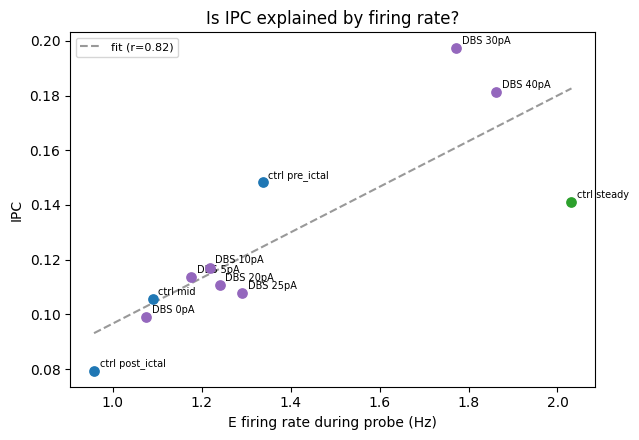


DBS 40pA: IPC=0.181, rate-predicted=0.169, residual=+0.013


In [13]:
import numpy as np, matplotlib.pyplot as plt
from scipy import stats
amps = [0.0, 5.0, 10.0, 20.0, 25.0, 30.0, 40.0]
def _get(d, *names):
    """First present key among names, else None."""
    for n in names:
        if n in d: return np.asarray(d[n])
    return None

conds = []
for amp in amps:
    r = sweep_one(amp)
    if r.get('found'):
        conds.append((f'DBS {amp:g}pA', r))
for k in ('post_ictal','mid','pre_ictal','steady'):
    e = res_ctrl['by_phase'].get(k, {})
    if e.get('found'):
        conds.append((f'ctrl {k}', e))

rows = []
for lbl, d in conds:
    ipc  = _get(d, 'ipc_total', 'ipc')
    pr   = _get(d, 'participation_ratio', 'pr')
    rate = _get(d, 'E_rate_probe')                       # may be None
    burst= _get(d, 'burst_during_probe')
    if ipc is None:
        print(f"{lbl:14s} no IPC - skipped"); continue
    ipc = ipc.astype(float)
    burst = burst.astype(bool) if burst is not None else np.zeros(len(ipc), bool)
    keep = ~burst
    if keep.sum() == 0:
        print(f"{lbl:14s} ALL {len(ipc)} probes bursting - excluded"); continue
    rate_m = float(rate.astype(float)[keep].mean()) if rate is not None else np.nan
    pr_m   = float(pr.astype(float)[keep].mean())   if pr   is not None else np.nan
    rows.append(dict(label=lbl, n=len(ipc), n_burst=int(burst.sum()),
                     ipc=float(ipc[keep].mean()), rate=rate_m, pr=pr_m,
                     ipc_all=ipc, keep=keep))
    tag = "" if rate is not None else "  (no rate)"
    print(f"{lbl:14s} rate={rate_m:6.2f}  IPC={rows[-1]['ipc']:.3f}  "
          f"PR={pr_m:5.1f}  bursting {int((~keep).sum())}/{len(ipc)}{tag}")

# regression only over conditions that actually have a rate
R = np.array([r['rate'] for r in rows])
I = np.array([r['ipc']  for r in rows])
ok = np.isfinite(R) & np.isfinite(I)
if ok.sum() < 3:
    print(f"\nOnly {ok.sum()} conditions have E_rate_probe - not enough for a rate "
          f"regression. Re-run the conditions you need with the E_rate_probe patch.")
else:
    sl, ic, rr, pp, se = stats.linregress(R[ok], I[ok])
    print(f"\nIPC ~ E_rate:  slope={sl:+.4f}  r={rr:.2f}  p={pp:.3f}  (n={ok.sum()})")

    fig, ax = plt.subplots(figsize=(6.5,4.5))
    xs = np.linspace(R[ok].min(), R[ok].max(), 50)
    ax.plot(xs, ic + sl*xs, '--', color='0.6', label=f'fit (r={rr:.2f})')
    for r in rows:
        if not np.isfinite(r['rate']): continue
        c = 'tab:green' if r['label']=='ctrl steady' else \
            ('tab:purple' if r['label'].startswith('DBS') else 'tab:blue')
        ax.scatter(r['rate'], r['ipc'], color=c, s=45, zorder=3)
        ax.annotate(r['label'], (r['rate'], r['ipc']), fontsize=7,
                    xytext=(4,3), textcoords='offset points')
    ax.set_xlabel('E firing rate during probe (Hz)'); ax.set_ylabel('IPC')
    ax.set_title('Is IPC explained by firing rate?'); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

    d40 = next((r for r in rows if r['label'].startswith('DBS 40')), None)
    if d40 and np.isfinite(d40['rate']):
        pred = ic + sl*d40['rate']
        print(f"\nDBS 40pA: IPC={d40['ipc']:.3f}, rate-predicted={pred:.3f}, "
              f"residual={d40['ipc']-pred:+.3f}")

In [65]:
import inspect, glob, pickle
print("--- live sweep_one saves keys ---")
src = inspect.getsource(sweep_one)
print("ipc_total" in src, "| 'ipc'-only:", "rec['ipc']" in src and "ipc_total" not in src)

print("--- cached files ---")
for f in sorted(glob.glob('results/dbs_sweep/*.pkl')):
    with open(f,'rb') as fh: r = pickle.load(fh)
    print(f.split('/')[-1], sorted(r.keys()))

--- live sweep_one saves keys ---
True | 'ipc'-only: False
--- cached files ---


In [ ]:
# import glob, os
# for f in glob.glob('results/dbs_sweep/*.pkl'):
#     os.remove(f)

In [49]:
rows = []
for lbl, d in conds:
    ipc   = np.asarray(d['ipc_total'], float)
    rate  = np.asarray(d['E_rate_probe'], float)
    pr    = np.asarray(d['participation_ratio'], float)
    burst = np.asarray(d['burst_during_probe'], bool)
    keep  = ~burst
    if keep.sum() == 0:                       # all probes bursted
        print(f"{lbl:14s} ALL {len(ipc)} probes bursting - excluded")
        continue
    rows.append(dict(label=lbl, n=len(ipc), n_burst=int(burst.sum()),
                     ipc=ipc[keep].mean(), rate=rate[keep].mean(),
                     pr=pr[keep].mean(),
                     ipc_all=ipc, rate_all=rate, keep=keep))
    print(f"{lbl:14s} rate={rows[-1]['rate']:.2f} Hz  IPC={rows[-1]['ipc']:.3f}  "
          f"PR={rows[-1]['pr']:5.1f}  bursting {burst.sum()}/{len(ipc)}")

R = np.array([r['rate'] for r in rows]); I = np.array([r['ipc'] for r in rows])
ok = np.isfinite(R) & np.isfinite(I)
sl, ic, rr, pp, se = stats.linregress(R[ok], I[ok])
print(f"\nIPC ~ E_rate:  slope={sl:+.4f}  r={rr:.2f}  p={pp:.3f}  (n={ok.sum()} conditions)")

fig, ax = plt.subplots(figsize=(6.5,4.5))
xs = np.linspace(R.min(), R.max(), 50)
ax.plot(xs, ic + sl*xs, '--', color='0.6', label=f'fit (r={rr:.2f})')
for r in rows:
    c = 'tab:purple' if r['label'].startswith('DBS') else 'tab:blue'
    if 'steady' in r['label'] and 'ctrl' in r['label']: c = 'tab:green'
    ax.scatter(r['rate'], r['ipc'], color=c, s=45, zorder=3)
    ax.annotate(r['label'], (r['rate'], r['ipc']), fontsize=7,
                xytext=(4,3), textcoords='offset points')
ax.set_xlabel('E firing rate during probe (Hz)'); ax.set_ylabel('IPC')
ax.set_title('Is IPC explained by firing rate?'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# residual of DBS 40 pA against the rate trend
d40 = next(r for r in rows if r['label'].startswith('DBS 40'))
pred = ic + sl*d40['rate']
print(f"\nDBS 40pA: IPC={d40['ipc']:.3f}, rate-predicted={pred:.3f}, "
      f"residual={d40['ipc']-pred:+.3f}")

KeyError: 'ipc_total'

In [ ]:
target_rate = d40['rate']          # e.g. ~2.3 Hz
for f in [40.0, 42.0, 44.0]:       # find the untreated freq matching that rate
    r = HSP_Phase.phase_capacity_seeded(net, f, seeds, phases=("mid",))
    bp = r["by_phase"]; key = "steady" if bp.get("steady",{}).get("found") else "mid"
    if not bp[key]['found']: continue
    rate = np.mean(bp[key]['E_rate_probe']); ipc = np.mean(bp[key]['ipc_total'])
    print(f"untreated {f} Hz: rate={rate:.2f}  IPC={ipc:.3f}  (target rate {target_rate:.2f})")

### Benzo PR

In [45]:
res_benzo = HSP_Phase.run_phase_replication(net, seeds, burst_freq_hz=36.0,
                                            steady_freq_hz=40.0,
                                            drug={'benzo': True, 'benzo_kGABA': 1.0})
b = res_benzo['by_phase']['steady']
print(f"benzo: IPC={np.mean(b['ipc_total']):.3f}  PR={np.mean(b['participation_ratio']):.1f}  "
      f"rate={np.mean(b['E_rate_probe']):.2f} Hz  bursting {np.sum(b['burst_during_probe'])}/10")

KeyError: 'E_rate_probe'

In [46]:
print(b)

{'ipc_total': array([0.09772605, 0.11895419, 0.12136528, 0.16706144, 0.13354104,
       0.1259128 , 0.10818555, 0.1279543 , 0.1403455 , 0.15436811]), 'linear_mc': array([0.09772605, 0.11174648, 0.10965849, 0.15241323, 0.13354104,
       0.10353249, 0.07449581, 0.1061277 , 0.10874093, 0.11597396]), 'nonlinear': array([0.        , 0.00720771, 0.0117068 , 0.01464822, 0.        ,
       0.02238031, 0.03368973, 0.02182661, 0.03160457, 0.03839415]), 'state_rank': array([100, 100, 100, 100, 100, 100, 100, 100, 100, 100]), 'participation_ratio': array([90.30052582, 90.39009664, 91.51585143, 91.16407658, 90.74955512,
       90.15930274, 91.14825441, 90.95768168, 90.28002816, 90.7696578 ]), 'burst_during_probe': array([False, False, False, False, False, False, False, False, False,
       False]), 'found': True, 'seeds': [11, 22, 33, 44, 55, 66, 77, 88, 99, 111], 'k_AMPA': 0.7639632431228097, 'k_GABA': 1.0}


### PR in full run

In [15]:
import numpy as np, matplotlib.pyplot as plt
from brian2 import second, Hz

def pr_from_counts(X):
    """PR from a (time_bins x neurons) count matrix. Same estimator as capacity_report."""
    X = np.asarray(X, float)
    X = X - X.mean(0)                      # center: covariance, not second moment
    if X.shape[0] < 2:
        return np.nan
    sv = np.linalg.svd(X, compute_uv=False)
    lam = sv ** 2
    s = lam.sum()
    return float(s * s / (lam ** 2).sum()) if s > 0 else np.nan

def pr_timecourse(net, input_freq_hz, drug=None, run_s=6000.0, warmup_s=2000.0,
                  bin_s=0.05, win_s=1, hop_s=0.5):
    """Live HSP run (nothing frozen). Returns PR(t) in sliding windows, plus r_est(t).
    bin_s : spike-count bin  |  win_s : covariance window  |  hop_s : step between windows
    """
    net.restore('baseline', filename='baseline_2hz.bri')
    net['inp'].rates = input_freq_hz * Hz
    HSP_Phase._apply_drugs(net, drug or {})
    rk = HSP_Phase._runkw(net)
    sp_E = net['sp_exc']; n_E = int(net['P_E'].N)
    rE_mon = net['rate_pop_mon_E']

    net.run(warmup_s * second, **rk)
    t0 = float(net.t / second)
    net.run(run_s * second, **rk)
    t1 = float(net.t / second)

    si = np.asarray(sp_E.i); st = np.asarray(sp_E.t / second)
    m = (st >= t0) & (st < t1); si, st = si[m], st[m] - t0

    # one global binning, then slice windows out of it (fast)
    n_bins = int((t1 - t0) / bin_s)
    edges = np.arange(n_bins + 1) * bin_s
    X = np.zeros((n_bins, n_E))
    for nrn in range(n_E):
        ts = st[si == nrn]
        if ts.size:
            X[:, nrn], _ = np.histogram(ts, bins=edges)

    w = int(win_s / bin_s); h = int(hop_s / bin_s)
    centers, pr, rate = [], [], []
    for a in range(0, n_bins - w + 1, h):
        seg = X[a:a + w]
        centers.append((a + w / 2) * bin_s)
        pr.append(pr_from_counts(seg))
        rate.append(seg.sum() / (n_E * win_s))          # Hz, same window
    return dict(t=np.array(centers), pr=np.array(pr), rate=np.array(rate),
                rE_t=np.asarray(rE_mon.t / second) - t0,
                rE=HSP_Phase._trace(rE_mon, 'r_pop_E'))

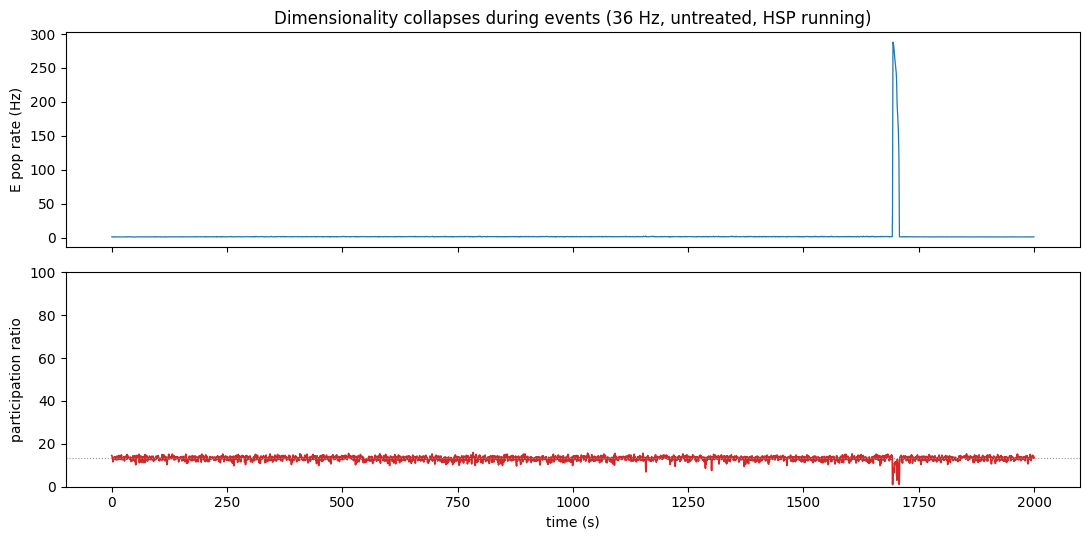

PR interictal (median) : 13.3
PR minimum (at burst)  : 1.0


In [16]:
tc = pr_timecourse(net, 36.0, run_s=2000.0)     # untreated bursting condition

fig, ax = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
ax[0].plot(tc['t'], tc['rate'], color='tab:blue', lw=.9)
ax[0].set_ylabel('E pop rate (Hz)'); ax[0].set_title(
    'Dimensionality collapses during events (36 Hz, untreated, HSP running)')
ax[1].plot(tc['t'], tc['pr'], color='tab:red', lw=1.2)
ax[1].axhline(np.nanmedian(tc['pr']), ls=':', color='0.6', lw=.8)
ax[1].set_ylabel('participation ratio'); ax[1].set_xlabel('time (s)')
ax[1].set_ylim(0, 100)
fig.tight_layout(); plt.show()

print(f"PR interictal (median) : {np.nanmedian(tc['pr']):.1f}")
print(f"PR minimum (at burst)  : {np.nanmin(tc['pr']):.1f}")

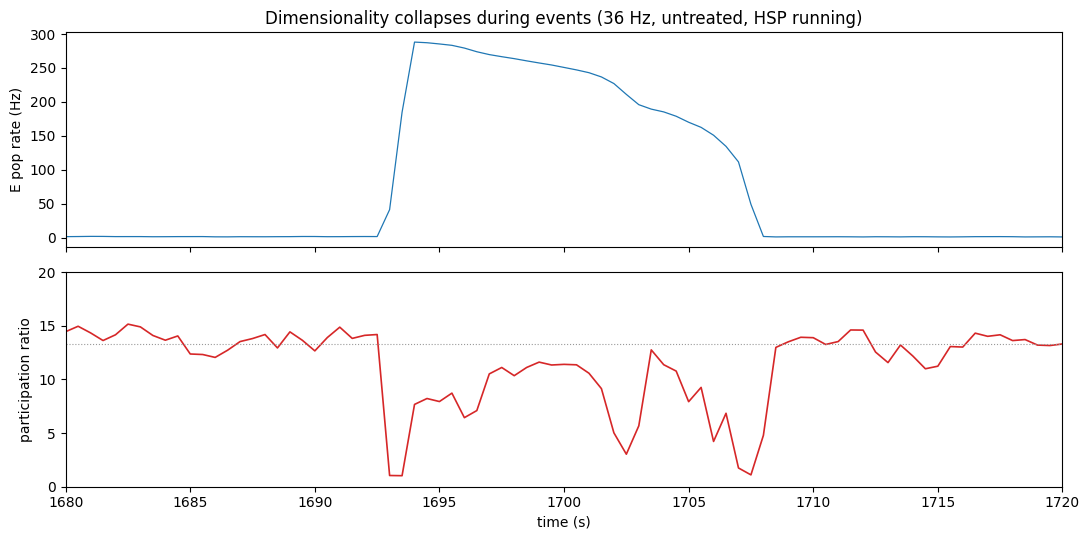

In [19]:
fig, ax = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
ax[0].plot(tc['t'], tc['rate'], color='tab:blue', lw=.9)
ax[0].set_ylabel('E pop rate (Hz)'); ax[0].set_title(
    'Dimensionality collapses during events (36 Hz, untreated, HSP running)')
ax[1].plot(tc['t'], tc['pr'], color='tab:red', lw=1.2)
ax[1].axhline(np.nanmedian(tc['pr']), ls=':', color='0.6', lw=.8)
ax[1].set_ylabel('participation ratio'); ax[1].set_xlabel('time (s)')
ax[1].set_ylim(0, 20)
ax[1].set_xlim(1680, 1720) 
fig.tight_layout(); plt.show()

In [ ]:
r40  = HSP_Phase.phase_capacity_seeded(net, 36.0, seeds, phases=("mid",),
         drug={'dbs': True, 'dbs_freq_hz': DBS_FREQ_HZ, 'dbs_amp_pA': 40.0})
rstd = HSP_Phase.phase_capacity_seeded(net, 40.0, seeds)

for lbl, bp in [('DBS 40pA', r40['by_phase']), ('ctrl steady', rstd['by_phase'])]:
    key = 'steady' if bp.get('steady', {}).get('found') else 'mid'
    d = bp[key]
    keep = ~np.asarray(d['burst_during_probe'], bool)
    print(#f"{lbl:12s} rate={np.mean(np.asarray(d['E_rate_probe'])[keep]):.2f} Hz  "
          f"IPC={np.mean(np.asarray(d['ipc_total'])[keep]):.3f}  "
          f"PR={np.mean(np.asarray(d['participation_ratio'])[keep]):.1f}  "
          f"burst {int((~keep).sum())}/{len(keep)}")

KeyError: 'E_rate_probe'

In [57]:
print(d)

{'ipc_total': array([0.15937578, 0.20338507, 0.1565506 , 0.20029371, 0.18475313,
       0.18158258, 0.14970484, 0.16462775, 0.18413386, 0.1620953 ]), 'linear_mc': array([0.15937578, 0.17317244, 0.13741447, 0.20029371, 0.15808432,
       0.15260655, 0.1280145 , 0.15618124, 0.15195953, 0.1515164 ]), 'nonlinear': array([0.        , 0.03021263, 0.01913612, 0.        , 0.0266688 ,
       0.02897603, 0.02169034, 0.0084465 , 0.03217433, 0.01057889]), 'state_rank': array([100, 100, 100, 100, 100, 100, 100, 100, 100, 100]), 'participation_ratio': array([84.43744348, 85.10700885, 87.68586901, 85.55196664, 85.44205398,
       85.42375182, 87.07160458, 85.82743557, 85.00626141, 86.06269279]), 'burst_during_probe': array([False, False, False, False, False, False, False, False, False,
       False]), 'found': True, 'seeds': [11, 22, 33, 44, 55, 66, 77, 88, 99, 111], 'k_AMPA': 0.8525701318922435, 'k_GABA': 0.12771407149622496}


In [56]:
print(#f"{lbl:12s} rate={np.mean(np.asarray(d['E_rate_probe'])[keep]):.2f} Hz  "
          f"IPC={np.mean(np.asarray(d['ipc_total'])[keep]):.3f}  "
          f"PR={np.mean(np.asarray(d['participation_ratio'])[keep]):.1f}  "
          f"burst {int((~keep).sum())}/{len(keep)}")

IPC=0.175  PR=85.8  burst 0/10


## Interpretation (honest to *this* model)

- DBS restores stability/firing by substituting **unstructured noisy drive** for the missing structured afferent input — recovering the operating point but not clean information flow. It does **not** reach the 40 Hz fixed point's capacity.
- **Do not** attribute the DBS-vs-steady gap to "lost neurons": this simplified model has reduced *drive* (36 vs 40 Hz), not a silenced subpopulation. The correct statement is the noise-to-signal substitution above.
- Therapy contrast = the payoff: **benzo decorrelates -> capacity up; DBS injects noise -> capacity down**, both suppress the seizure. On a seizure-power vs IPC scatter, benzo sits left-and-level/up, DBS below-left.
- Whether DBS lands above or below untreated `ctrl_mid` is amplitude-dependent (let the sweep decide); either way it sits below steady, which is the claim.
- Clamp/dose note carried over from benzo: log operating points and prefer graded doses so effects aren't confounded by manipulation magnitude.